# Cognifyz Data Analysis Internship

## Data Analysis using Python

### Intern Details
- **Name:** Kishu Agarwal

---

## Project Objective

The objective of this project is to analyze the restaurant dataset and extract meaningful insights using Python. The analysis includes data cleaning, exploratory data analysis (EDA), visualization, and business insights based on various restaurant attributes such as cuisines, cities, ratings, price ranges, online delivery, and restaurant chains.

---

## Tools & Libraries

- Python
- Pandas
- Matplotlib
- Google Colab

---

## Dataset

The dataset contains information about restaurants, including their names, cuisines, ratings, votes, locations, price ranges, online delivery, and other useful attributes.

In [2]:
# Import Libraries

import pandas as pd
import matplotlib.pyplot as plt

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [3]:
# Upload Dataset

from google.colab import files

uploaded = files.upload()

Saving Dataset .csv to Dataset .csv


In [4]:
import os

# Display uploaded file names
print("Uploaded Files:")
print(os.listdir())

df = pd.read_csv(next(iter(uploaded)))

# Display first five rows
df.head()

Uploaded Files:
['.config', 'Dataset .csv', 'sample_data']


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [5]:
#dataset overview
print("Shape of Dataset:", df.shape)

print("\nColumn Names:\n")
print(df.columns.tolist())

Shape of Dataset: (9551, 21)

Column Names:

['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


## Level 1 - Task 1: Top Cuisines

**Objective:** Find the top 3 most common cuisines and calculate their percentage in the dataset.

In [6]:
cuisine_data = df['Cuisines'].dropna().str.split(', ')

all_cuisines = cuisine_data.explode()

# Find top 3 cuisines
top3 = all_cuisines.value_counts().head(3)

print("Top 3 Most Common Cuisines")
print(top3)

Top 3 Most Common Cuisines
Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Name: count, dtype: int64


In [7]:
total_restaurants = len(df)

percentage = (top3 / total_restaurants) * 100

percentage = percentage.round(2)

print("Percentage of Restaurants Serving Top Cuisines\n")

print(percentage)

Percentage of Restaurants Serving Top Cuisines

Cuisines
North Indian    41.46
Chinese         28.64
Fast Food       20.79
Name: count, dtype: float64


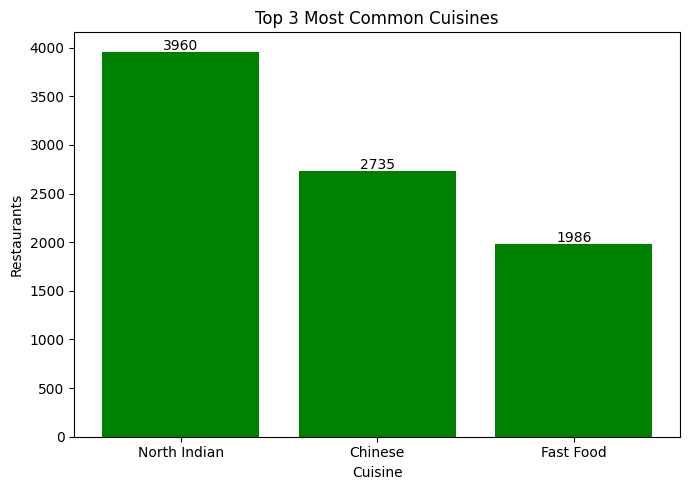

In [8]:
plt.figure(figsize=(7,5))

bars = plt.bar(top3.index, top3.values, color='green')

plt.title("Top 3 Most Common Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Restaurants")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 20,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()

### Insights

- The above chart shows the three most common cuisines in the dataset
- The percentage indicates how frequently these cuisines are served

### Conclusion

North Indian, Chinese, and Fast Food are the most common cuisines in the dataset. These cuisines are served by a large percentage of restaurants, indicating their popularity.

## Level 1 - Task 2: City Analysis

**Objective:** Identify the city with the highest number of restaurants, calculate the average rating for each city, and determine the city with the highest average rating.

In [9]:
# Count restaurants in each city
city_count = df['City'].value_counts()

print("Restaurant Count by City\n")
print(city_count)

print("\nCity with Highest Number of Restaurants:")
print(f"{city_count.idxmax()} ({city_count.max()} restaurants)")

Restaurant Count by City

City
New Delhi         5473
Gurgaon           1118
Noida             1080
Faridabad          251
Ghaziabad           25
                  ... 
Lakes Entrance       1
Mohali               1
Panchkula            1
Bandung              1
Randburg             1
Name: count, Length: 141, dtype: int64

City with Highest Number of Restaurants:
New Delhi (5473 restaurants)


In [13]:
# Calculating average rating for each city
average_rating = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)

print()
print("Average Rating of Each City\n")
print(average_rating)


Average Rating of Each City

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
                      ...   
New Delhi           2.438845
Montville           2.400000
Mc Millan           2.400000
Noida               2.036204
Faridabad           1.866932
Name: Aggregate rating, Length: 141, dtype: float64


In [14]:
# Finding the city with the highest average rating
print("City with Highest Average Rating:\n")
print(f"{average_rating.idxmax()} ({average_rating.max():.2f})")

City with Highest Average Rating:

Inner City (4.90)


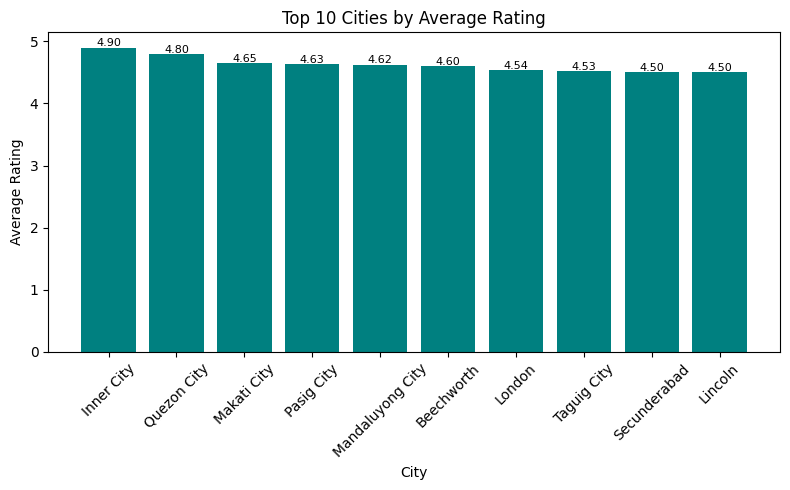

In [15]:
# Visualize top 10 cities by average rating
top10_rating = average_rating.head(10)

plt.figure(figsize=(8,5))

bars = plt.bar(top10_rating.index, top10_rating.values, color='teal')

plt.title("Top 10 Cities by Average Rating")
plt.xlabel("City")
plt.ylabel("Average Rating")

plt.xticks(rotation=45)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.2f}",
        ha='center',
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Insights

- New Delhi has the highest number of restaurants, with 5,473 restaurants
- Average ratings differ across cities, showing variations in customer satisfaction
- Inner City has the highest average restaurant rating of 4.90

### Conclusion

The analysis shows that New Delhi has the largest restaurant presence, while Inner City has the highest average rating. This indicates that a higher number of restaurants does not necessarily result in higher customer ratings

## Level 1 - Task 3: Price Range Distribution

**Objective:** Analyze the distribution of restaurants across different price ranges and calculate their percentage.

In [16]:
# Count restaurants in each price range
price_count = df['Price range'].value_counts().sort_index()

print("Restaurant Count by Price Range\n")
print(price_count)

Restaurant Count by Price Range

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


In [17]:
# Calculating percentage for each price range
price_percentage = (price_count / len(df)) * 100

print("Percentage of Restaurants in Each Price Range\n")
print(price_percentage.round(2))

Percentage of Restaurants in Each Price Range

Price range
1    46.53
2    32.59
3    14.74
4     6.14
Name: count, dtype: float64


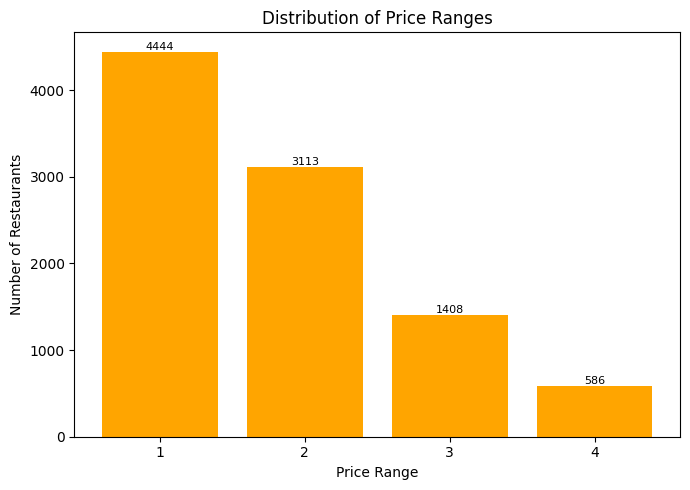

In [18]:
# Visualizing restaurant distribution by price range
plt.figure(figsize=(7,5))

bars = plt.bar(
    price_count.index.astype(str),
    price_count.values,
    color='orange'
)

plt.title("Distribution of Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 20,
        str(bar.get_height()),
        ha='center',
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Insights

- Price Range 1 has the highest number of restaurants (4,444), representing 46.53% of the dataset
- Price Range 4 has the lowest number of restaurants (586), accounting for only 6.14%
- Most restaurants belong to the lower price categories, while premium-priced restaurants are comparatively fewer

### Conclusion

The analysis indicates that most restaurants fall under the lower price ranges, whereas higher price ranges contain fewer restaurants. This suggests that affordable dining options are more common in the dataset...

# Level 1 - Task 4: Online Delivery

**Objective:** Analyze online delivery availability and compare customer ratings based on delivery service

In [19]:
# Count restaurants with and without online delivery
delivery_count = df['Has Online delivery'].value_counts()

print("Number of Restaurants by Online Delivery\n")
print(delivery_count)

Number of Restaurants by Online Delivery

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [20]:
# calculate percentage of restaurants with & without online delivery
delivery_count = df['Has Online delivery'].value_counts()

delivery_percentage = (delivery_count / len(df) * 100).round(2)

print("Percentage of Restaurants by Online Delivery\n")
print(delivery_percentage)

Percentage of Restaurants by Online Delivery

Has Online delivery
No     74.34
Yes    25.66
Name: count, dtype: float64


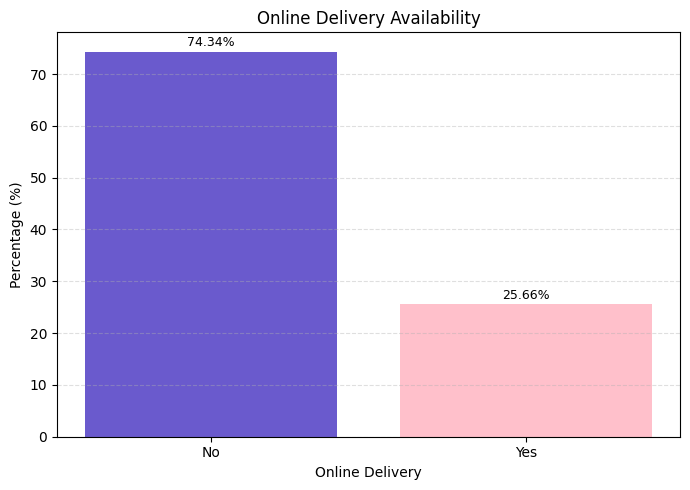

In [21]:
# Visualizing percentage of restaurants offering online delivery

plt.figure(figsize=(7,5))

bars = plt.bar(
    delivery_percentage.index,
    delivery_percentage.values,
    color=['slateblue','pink']
)

plt.title("Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Percentage (%)")

# Display percentage values
for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+1,
        f"{bar.get_height():.2f}%",
        ha='center',
        fontsize=9
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [22]:
# Comparing the average ratings based on online delivery
delivery_rating = df.groupby('Has Online delivery')['Aggregate rating'].mean().round(2)

print("Average Rating by Online Delivery\n")
print(delivery_rating)

Average Rating by Online Delivery

Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64


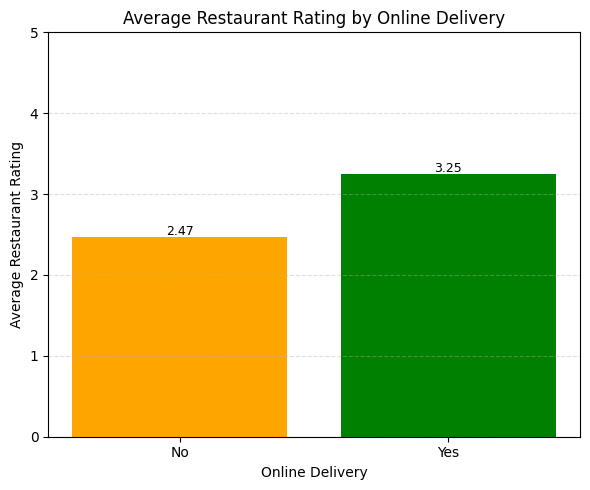

In [23]:
# Visualizing average ratings
plt.figure(figsize=(6,5))

bars = plt.bar(
    delivery_rating.index,
    delivery_rating.values,
    color=['orange', 'green']
)

plt.title("Average Restaurant Rating by Online Delivery")
plt.xlabel("Online Delivery")
plt.ylabel("Average Restaurant Rating")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.2f}",
        ha='center',
        fontsize=9
    )

plt.ylim(0,5)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Insights

- Around 74.34% of restaurants do not offer online delivery
- Only 25.66% of restaurants provide online delivery services
- Restaurants offering online delivery have a higher average rating (3.25) than those without online delivery (2.47)

### Conclusion

The analysis shows that although most restaurants do not offer online delivery, the restaurants that do provide this service receive higher average ratings. This suggests that online delivery may positively influence customer experience and satisfaction...